In [ ]:
DRIVE_PATH = "/content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/Week3"
YOLO_MODEL_NAME = "yolov8n-roadguard.onnx"
INPUT_ZIP_PATH = "RDD2022.v2i.yolov8.zip"

In [10]:
import sys
import subprocess

# 1. Automatic installation of missing third-party environments
try:
    from ultralytics import YOLO
    import yaml
except ModuleNotFoundError:
    print("Installing missing dependencies...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics", "onnxruntime-gpu", "pyyaml", "tqdm"])
    from ultralytics import YOLO
    import yaml

import os
import json
import zipfile
import shutil
import random
from pathlib import Path
from tqdm import tqdm
from google.colab import drive

# 2. Establish Google Drive connection
print("Connecting to Google Drive...")
drive.mount('/content/drive')

# ================= Configuration and Paths =================
DRIVE_PATH = "/content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3"

YOLO_MODEL_NAME = "yolov8n-roadguard.onnx"
YOLO_MODEL_PATH = os.path.join(DRIVE_PATH, YOLO_MODEL_NAME)

YOLO_YAML_NAME = "data.yaml"
YOLO_YAML_PATH = os.path.join(DRIVE_PATH, YOLO_YAML_NAME)

INPUT_ZIP_PATH = os.path.join(DRIVE_PATH, "RDD2022.v2i.yolov8.zip")
OUTPUT_ZIP_PATH = os.path.join(DRIVE_PATH, "filtered_dataset.zip")

CONFIDENCE_THRESHOLD = 0.8
SAMPLE_SIZE = 200
# ===========================================================

TEMP_EXTRACT_DIR = Path("temp_extracted_images")
TEMP_ALL_VALID_DIR = Path("temp_all_valid_output")
TEMP_FINAL_SAMPLE_DIR = Path("temp_final_sample_output")

def load_classes_from_yaml(yaml_path):
    """Loads class definitions directly from the target dataset YAML configuration."""
    if not os.path.exists(yaml_path):
        print(f"[!] Warning: YAML file not found at {yaml_path}. Using fallback profiles.")
        return None
    try:
        with open(yaml_path, 'r', encoding='utf-8') as f:
            data = yaml.safe_load(f)
            if 'names' in data:
                if isinstance(data['names'], list):
                    return {i: name for i, name in enumerate(data['names'])}
                elif isinstance(data['names'], dict):
                    return {int(k): v for k, v in data['names'].items()}
    except Exception as e:
        print(f"[!] Error reading YAML file: {e}")
    return None

def main():
    if not os.path.exists(YOLO_MODEL_PATH):
        print(f"Error: YOLO weights file not found at {YOLO_MODEL_PATH}")
        return

    print(f"Loading YOLO ONNX model from {YOLO_MODEL_PATH}...")
    model = YOLO(YOLO_MODEL_PATH)

    class_names_dict = load_classes_from_yaml(YOLO_YAML_PATH) or model.names
    print(f"[+] Loaded class names mapping: {class_names_dict}")

    # Initialize clean, empty temporary local staging areas
    for folder in [TEMP_EXTRACT_DIR, TEMP_ALL_VALID_DIR, TEMP_FINAL_SAMPLE_DIR]:
        if folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True, exist_ok=True)

    valid_images_dir = TEMP_ALL_VALID_DIR / "images"
    valid_labels_dir = TEMP_ALL_VALID_DIR / "labels"
    valid_json_dir = TEMP_ALL_VALID_DIR / "json_info"

    for d in [valid_images_dir, valid_labels_dir, valid_json_dir]:
        d.mkdir(parents=True, exist_ok=True)

    if not os.path.exists(INPUT_ZIP_PATH):
        print(f"Error: Input file {INPUT_ZIP_PATH} not found.")
        return

    print(f"Extracting {INPUT_ZIP_PATH}...")
    with zipfile.ZipFile(INPUT_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(TEMP_EXTRACT_DIR)

    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    image_paths = [p for p in TEMP_EXTRACT_DIR.rglob("*") if p.suffix.lower() in image_extensions]
    num_images = len(image_paths)
    print(f"Found {num_images} images to process.")

    valid_records = []

    print("\nPhase 1: Running inference and filtering dataset...")
    for img_path in tqdm(image_paths, desc="Processing images", total=num_images):
        # FIXED: Extracting the first element [0] from the results list to prevent AttributeError
        results = model(img_path, verbose=False)[0]
        boxes = results.boxes

        if boxes is None or len(boxes) == 0:
            continue

        all_above_thresh = all(conf > CONFIDENCE_THRESHOLD for conf in boxes.conf)

        if all_above_thresh:
            relative_path = img_path.relative_to(TEMP_EXTRACT_DIR)
            flat_name = str(relative_path).replace(os.sep, "_")
            flat_stem = Path(flat_name).stem

            valid_records.append({"flat_name": flat_name, "flat_stem": flat_stem})
            shutil.copy(img_path, valid_images_dir / flat_name)

            # Save YOLO text descriptors incorporating raw confidence maps (6 items per line)
            label_file_path = valid_labels_dir / f"{flat_stem}.txt"
            objects_metadata = []

            with open(label_file_path, "w") as lf:
                for box in boxes:
                    class_id = int(box.cls.item())
                    conf_value = float(box.conf.item())
                    xywhn = box.xywhn.tolist()[0] if box.xywhn.ndim > 1 else box.xywhn.tolist()

                    line = f"{class_id} " + " ".join(f"{val:.6f}" for val in xywhn) + f" {conf_value:.6f}\n"
                    lf.write(line)

                    objects_metadata.append({
                        "class_id": class_id,
                        "class_name": class_names_dict.get(class_id, f"unknown_{class_id}"),
                        "confidence": conf_value,
                        "bbox_xywhn": xywhn,
                        "relative_area": float(xywhn[2] * xywhn[3])
                    })

            # Save complete per-image JSON report tracking relational context
            json_file_path = valid_json_dir / f"{flat_stem}.json"
            json_data = {
                "image_name": flat_name,
                "relative_image_path": f"images/{flat_name}",
                "relative_label_path": f"labels/{flat_stem}.txt",
                "total_objects": len(objects_metadata),
                "objects": objects_metadata
            }
            with open(json_file_path, "w", encoding="utf-8") as jf:
                json.dump(json_data, jf, indent=4, ensure_ascii=False)

    total_valid = len(valid_records)
    print(f"\nValidation phase complete. Found {total_valid} images meeting the criteria.")

    if total_valid > 0:
        actual_sample_size = min(SAMPLE_SIZE, total_valid)
        print(f"\nPhase 2: Randomly sampling {actual_sample_size} images...")
        sampled_records = random.sample(valid_records, actual_sample_size)

        final_images_dir = TEMP_FINAL_SAMPLE_DIR / "images"
        final_labels_dir = TEMP_FINAL_SAMPLE_DIR / "labels"
        final_json_dir = TEMP_FINAL_SAMPLE_DIR / "json_info"

        for d in [final_images_dir, final_labels_dir, final_json_dir]:
            d.mkdir(parents=True, exist_ok=True)

        global_summary_data = {
            "dataset_metadata": {
                "confidence_threshold": CONFIDENCE_THRESHOLD,
                "sample_size_requested": SAMPLE_SIZE,
                "sample_size_actual": actual_sample_size,
                "total_valid_pool_size": total_valid
            },
            "sampled_images_registry": {}
        }

        # Build relational links and copy files to sample destination
        for record in tqdm(sampled_records, desc="Copying sampled data"):
            img_file = record["flat_name"]
            name_stem = record["flat_stem"]

            shutil.copy(valid_images_dir / img_file, final_images_dir / img_file)
            shutil.copy(valid_labels_dir / f"{name_stem}.txt", final_labels_dir / f"{name_stem}.txt")
            shutil.copy(valid_json_dir / f"{name_stem}.json", final_json_dir / f"{name_stem}.json")

            # Map relational info into global registry for seamless analytical loading
            with open(final_json_dir / f"{name_stem}.json", "r", encoding="utf-8") as jf:
                global_summary_data["sampled_images_registry"][name_stem] = json.load(jf)

        # Export master database sheet to root directory
        master_summary_path = TEMP_FINAL_SAMPLE_DIR / "global_summary.json"
        with open(master_summary_path, "w", encoding="utf-8") as mjf:
            json.dump(global_summary_data, mjf, indent=4, ensure_ascii=False)

        print(f"\nPhase 3: Creating new ZIP archive at: {OUTPUT_ZIP_PATH}...")
        total_files_to_zip = sum([len(files) for r, d, files in os.walk(TEMP_FINAL_SAMPLE_DIR)])

        with zipfile.ZipFile(OUTPUT_ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zipf:
            with tqdm(total=total_files_to_zip, desc="Zipping files") as pbar:
                for root, dirs, files_in_dir in os.walk(TEMP_FINAL_SAMPLE_DIR):
                    for file in files_in_dir:
                        file_path = Path(root) / file
                        arcname = file_path.relative_to(TEMP_FINAL_SAMPLE_DIR)
                        zipf.write(file_path, arcname)
                        pbar.update(1)
        print("\nThe new ZIP has been saved successfully in your Google Drive.")
    else:
        print("No images matched the criteria, output ZIP was not created.")

    print("\nCleaning up temporary workspace...")
    for folder in [TEMP_EXTRACT_DIR, TEMP_ALL_VALID_DIR, TEMP_FINAL_SAMPLE_DIR]:
        shutil.rmtree(folder)
    print("Temporary local folders cleaned up. Done!")

if __name__ == "__main__":
    main()

Connecting to Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading YOLO ONNX model from /content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3/yolov8n-roadguard.onnx...
[!] Warning: YAML file not found at /content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3/data.yaml. Using fallback profiles.
Loading /content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3/yolov8n-roadguard.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CUDAExecutionProvider
[+] Loaded class names mapping: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40'}
Extracting /content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3/RDD2022.v2i.yolov8.zip...
Found 17439 images to process.

Phase 1: Running inference and filtering dataset...


Processing images:   0%|          | 0/17439 [00:00<?, ?it/s]

Loading /content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3/yolov8n-roadguard.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CUDAExecutionProvider


Processing images: 100%|██████████| 17439/17439 [03:01<00:00, 96.02it/s]



Validation phase complete. Found 197 images meeting the criteria.

Phase 2: Randomly sampling 197 images...


Copying sampled data: 100%|██████████| 197/197 [00:00<00:00, 1530.84it/s]



Phase 3: Creating new ZIP archive at: /content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3/filtered_dataset.zip...


Zipping files: 100%|██████████| 592/592 [00:00<00:00, 776.75it/s]



The new ZIP has been saved successfully in your Google Drive.

Cleaning up temporary workspace...
Temporary local folders cleaned up. Done!


Connecting to Google Drive...
Mounted at /content/drive
Extracting statistical data from global_summary.json inside the ZIP...


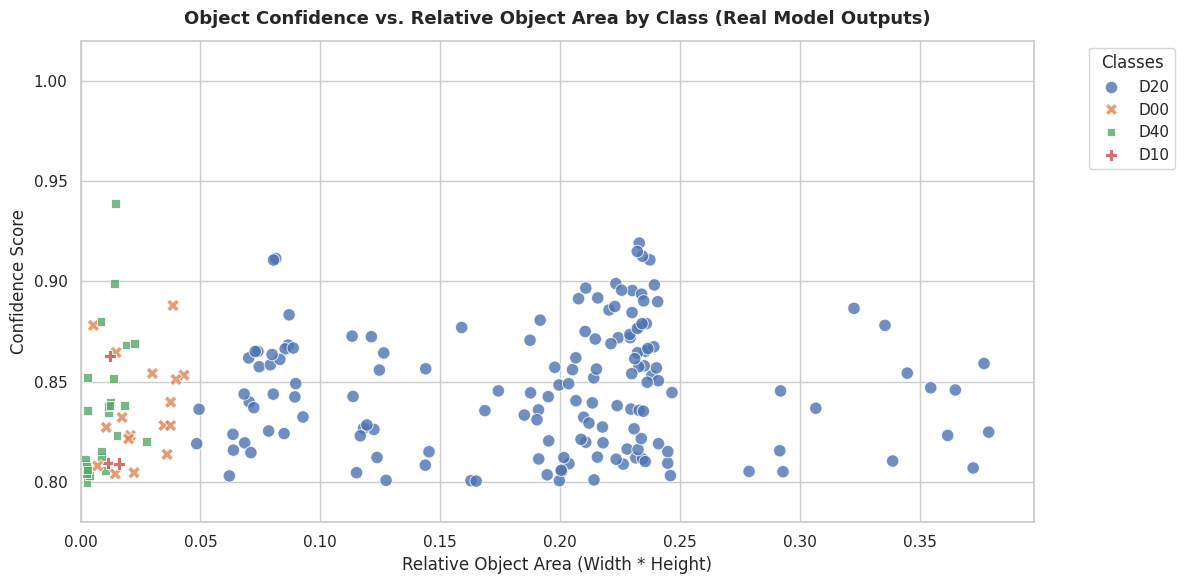

In [3]:
import os
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 2. Establish Google Drive connection
print("Connecting to Google Drive...")
drive.mount('/content/drive')

# ================= Configuration and Paths =================
DRIVE_PATH = "/content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3"
FILTERED_ZIP_PATH = os.path.join(DRIVE_PATH, "filtered_dataset.zip")
# ===========================================================

def main():
    if not os.path.exists(FILTERED_ZIP_PATH):
        print(f"Error: Filtered ZIP file not found at {FILTERED_ZIP_PATH}")
        return

    print("Extracting statistical data from global_summary.json inside the ZIP...")
    stats_list = []

    # Read data directly from the generated global JSON database sheet
    with zipfile.ZipFile(FILTERED_ZIP_PATH, 'r') as archive:
        if "global_summary.json" in archive.namelist():
            with archive.open("global_summary.json") as f:
                summary_data = json.load(f)

            # Parse registry contextual profiles
            registry = summary_data.get("sampled_images_registry", {})
            for img_stem, img_data in registry.items():
                for obj in img_data.get("objects", []):
                    stats_list.append({
                        "class_name": obj.get("class_name"),
                        "confidence": obj.get("confidence"),
                        "area": obj.get("relative_area")
                    })
        else:
            print("Error: global_summary.json was not found in the root of the ZIP file.")
            return

    # Generate analytical scatter plot
    if stats_list:
        df = pd.DataFrame(stats_list)

        plt.figure(figsize=(12, 6))
        sns.set_theme(style="whitegrid")

        # Plot accurate confidence score vs object relative area mapped by class
        sns.scatterplot(
            data=df,
            x='area',
            y='confidence',
            hue='class_name',
            style='class_name',
            alpha=0.8,
            s=80
        )

        plt.title("Object Confidence vs. Relative Object Area by Class (Real Model Outputs)", fontsize=13, fontweight='bold', pad=12)
        plt.xlabel("Relative Object Area (Width * Height)")
        plt.ylabel("Confidence Score")
        plt.xlim(left=0)
        plt.ylim(df['confidence'].min() - 0.02, 1.02)
        plt.legend(title="Classes", bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()
    else:
        print("No valid statistical object parameters could be parsed.")

if __name__ == "__main__":
    main()

In [4]:
import os
import zipfile
from collections import defaultdict

# ================= Configuration and Paths =================
DRIVE_PATH = "/content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3"
FILTERED_ZIP_PATH = os.path.join(DRIVE_PATH, "filtered_dataset.zip")
# ===========================================================

def print_zip_structure():
    if not os.path.exists(FILTERED_ZIP_PATH):
        print(f"Error: Target ZIP file not found at {FILTERED_ZIP_PATH}")
        return

    print(f"Analyzing ZIP Archive: {os.path.basename(FILTERED_ZIP_PATH)}\n")
    print("filtered_dataset.zip/")

    # Dictionary to group nested files by their parent directories
    tree = defaultdict(list)
    root_files = []

    with zipfile.ZipFile(FILTERED_ZIP_PATH, 'r') as archive:
        for name in archive.namelist():
            if '/' in name:
                parts = name.split('/')
                parent_dir = parts[0]
                file_name = '/'.join(parts[1:])
                if file_name:  # Ensure it is a file and not an empty directory slot
                    tree[parent_dir].append(file_name)
            else:
                root_files.append(name)

    # 1. Print structured subdirectories and a preview of their contents
    for folder, files in sorted(tree.items()):
        print(f"├── {folder}/")
        # Display the first 3 files as a sample preview, then truncate the rest
        preview_limit = 3
        for file in files[:preview_limit]:
            print(f"│   ├── {file}")
        if len(files) > preview_limit:
            print(f"│   └── ... ({len(files) - preview_limit} more files)")

    # 2. Print root level database/summary files
    for file in sorted(root_files):
        print(f"└── {file}")

if __name__ == "__main__":
    print_zip_structure()

Analyzing ZIP Archive: filtered_dataset.zip

filtered_dataset.zip/
├── images/
│   ├── train_images_India_006820_jpg.rf.ecf5c5e5ee724dc5a37f9f2168938de7.jpg
│   ├── train_images_India_008325_jpg.rf.e8b1cf29171a083e22b466514ca1d53b.jpg
│   ├── train_images_India_008325_jpg.rf.ab710ff8e66529d5b2f862b4da894407.jpg
│   └── ... (194 more files)
├── json_info/
│   ├── train_images_India_009000_jpg.rf.fa104918b817d428d051daac83fb9924.json
│   ├── train_images_India_008677_jpg.rf.6d90482a061b54538dee56e53353a49c.json
│   ├── train_images_India_007404_jpg.rf.dae69bcde4e760f2e5ad30a062aa042b.json
│   └── ... (194 more files)
├── labels/
│   ├── train_images_United_States_003885_jpg.rf.f5796bd225c5758e517a806a48215a77.txt
│   ├── valid_images_India_007476_jpg.rf.cea607f0c49cab0399897eec5e3786bc.txt
│   ├── train_images_India_004006_jpg.rf.4ff43ea654b05f7130b9845fe9e1cda4.txt
│   └── ... (194 more files)
└── global_summary.json


In [5]:
import os
import zipfile
import json

# ================= Configuration and Paths =================
DRIVE_PATH = "/content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3"
FILTERED_ZIP_PATH = os.path.join(DRIVE_PATH, "filtered_dataset.zip")
# ===========================================================

def inspect_json_schemas():
    if not os.path.exists(FILTERED_ZIP_PATH):
        print(f"Error: Target ZIP file not found at {FILTERED_ZIP_PATH}")
        return

    with zipfile.ZipFile(FILTERED_ZIP_PATH, 'r') as archive:
        file_list = archive.namelist()

        # 1. Locate and display a single per-image JSON schema sample
        json_info_files = [f for f in file_list if f.endswith('.json') and 'json_info' in f]

        print("=" * 60)
        print("1. INDIVIDUAL IMAGE JSON SCHEMA (Example from json_info/)")
        print("=" * 60)

        if json_info_files:
            sample_json_path = json_info_files[0]
            print(f"Source file inside ZIP: {sample_json_path}\n")
            with archive.open(sample_json_path) as jf:
                sample_data = json.load(jf)
                print(json.dumps(sample_data, indent=4, ensure_ascii=False))
        else:
            print("[!] No individual image JSON files found in json_info/ directory.")

        print("\n" + "=" * 60)
        print("2. GLOBAL MASTER SUMMARY JSON SCHEMA (Root Level file)")
        print("=" * 60)

        # 2. Locate and display the structural skeleton of the global master sheet
        if "global_summary.json" in file_list:
            print("Source file inside ZIP: global_summary.json\n")
            with archive.open("global_summary.json") as mjf:
                master_data = json.load(mjf)

            # Truncate the massive registry lists to show just the structural schema architecture
            registry_keys = list(master_data.get("sampled_images_registry", {}).keys())
            if registry_keys:
                sample_key = registry_keys[0]
                truncated_registry = {
                    sample_key: master_data["sampled_images_registry"][sample_key],
                    "...": f"({len(registry_keys) - 1} more identical image database entries mapped dynamically)"
                }
            else:
                truncated_registry = {}

            schema_skeleton = {
                "dataset_metadata": master_data.get("dataset_metadata"),
                "sampled_images_registry": truncated_registry
            }

            print(json.dumps(schema_skeleton, indent=4, ensure_ascii=False))
        else:
            print("[!] global_summary.json was not found in the root directory of the ZIP.")

if __name__ == "__main__":
    inspect_json_schemas()

1. INDIVIDUAL IMAGE JSON SCHEMA (Example from json_info/)
Source file inside ZIP: json_info/train_images_India_009000_jpg.rf.fa104918b817d428d051daac83fb9924.json

{
    "image_name": "train_images_India_009000_jpg.rf.fa104918b817d428d051daac83fb9924.jpg",
    "relative_image_path": "images/train_images_India_009000_jpg.rf.fa104918b817d428d051daac83fb9924.jpg",
    "relative_label_path": "labels/train_images_India_009000_jpg.rf.fa104918b817d428d051daac83fb9924.txt",
    "total_objects": 1,
    "objects": [
        {
            "class_id": 2,
            "class_name": "D20",
            "confidence": 0.8584888577461243,
            "bbox_xywhn": [
                0.45901021361351013,
                0.6172627806663513,
                0.29587018489837646,
                0.267564594745636
            ],
            "relative_area": 0.07916438611965049
        }
    ]
}

2. GLOBAL MASTER SUMMARY JSON SCHEMA (Root Level file)
Source file inside ZIP: global_summary.json

{
    "dataset_me

DATASET OBJECT DENSITY STATISTICS
Total sampled images analyzed : 197
Average objects per image     : 1.01
Median objects per image      : 1
Maximum objects in one image  : 2



/tmp/ipykernel_4889/4119447246.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=df_counts, palette="viridis")


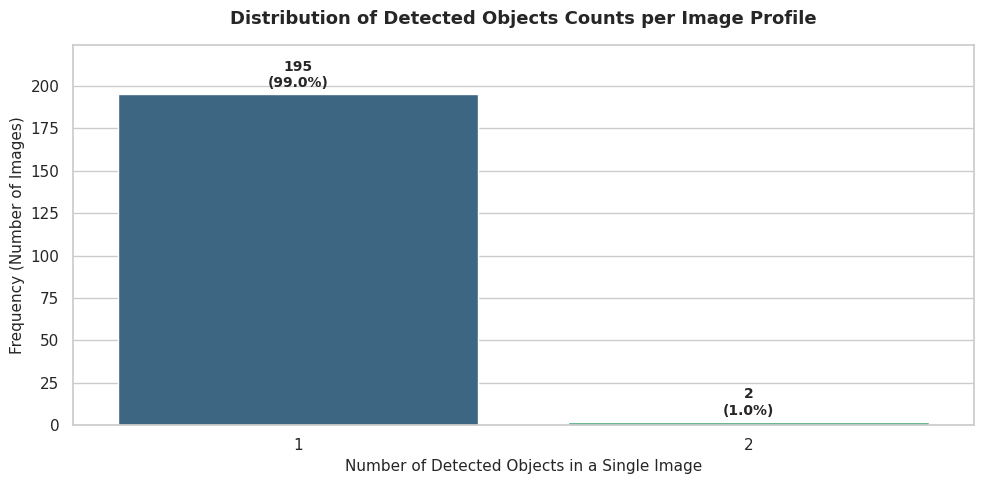

In [7]:
import os
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ================= Configuration and Paths =================
DRIVE_PATH = "/content/drive/MyDrive/DtaSc26/Fin_Proj_Rob/week3"
FILTERED_ZIP_PATH = os.path.join(DRIVE_PATH, "filtered_dataset.zip")
# ===========================================================

def plot_object_distribution_per_image():
    if not os.path.exists(FILTERED_ZIP_PATH):
        print(f"Error: Target ZIP file not found at {FILTERED_ZIP_PATH}")
        return

    object_counts = []

    # Extract object count statistics directly from the global summary database
    with zipfile.ZipFile(FILTERED_ZIP_PATH, 'r') as archive:
        if "global_summary.json" in archive.namelist():
            with archive.open("global_summary.json") as f:
                summary_data = json.load(f)

            registry = summary_data.get("sampled_images_registry", {})
            for img_stem, img_data in registry.items():
                # Extract total_objects metric per image profile
                object_counts.append(img_data.get("total_objects", 0))
        else:
            print("Error: global_summary.json was not found in the root of the ZIP file.")
            return

    if object_counts:
        # Convert to Pandas Series for seamless statistical aggregation
        df_counts = pd.Series(object_counts, name="Objects per Image")

        # Calculate summary statistics
        avg_objs = df_counts.mean()
        median_objs = df_counts.median()
        max_objs = df_counts.max()

        print("=" * 50)
        print("DATASET OBJECT DENSITY STATISTICS")
        print("=" * 50)
        print(f"Total sampled images analyzed : {len(df_counts)}")
        print(f"Average objects per image     : {avg_objs:.2f}")
        print(f"Median objects per image      : {int(median_objs)}")
        print(f"Maximum objects in one image  : {max_objs}")
        print("=" * 50 + "\n")

        # Generate the visualization plot
        plt.figure(figsize=(10, 5))
        sns.set_theme(style="whitegrid")

        # Plot discrete frequency counts of objects per image
        ax = sns.countplot(x=df_counts, palette="viridis")

        # Annotate bars with exact counts and relative percentages
        total_images = len(df_counts)
        for p in ax.patches:
            height = p.get_height()
            if height > 0:
                percentage = (height / total_images) * 100
                ax.annotate(f'{int(height)}\n({percentage:.1f}%)',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='bottom', fontsize=10,
                            fontweight='bold', xytext=(0, 3),
                            textcoords='offset points')

        plt.title("Distribution of Detected Objects Counts per Image Profile", fontsize=13, fontweight='bold', pad=15)
        plt.xlabel("Number of Detected Objects in a Single Image", fontsize=11)
        plt.ylabel("Frequency (Number of Images)", fontsize=11)
        plt.ylim(0, df_counts.value_counts().max() * 1.15)  # Pad upper limit for text layout
        plt.tight_layout()
        plt.show()
    else:
        print("[!] No operational object indicators found to aggregate.")

if __name__ == "__main__":
    plot_object_distribution_per_image()